#STEP A1: ENVIRONMENT SET-UP

In [ ]:
# GPU CHECK
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu128 True Tesla T4


In [ ]:
# MOUNT GOOGLE DRIVE
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#REQUIRED LIBRARIES
!pip install -q torchvision scikit-learn matplotlib split-folders seaborn

#STEP A2: DATASET PREPARATION

In [ ]:
from google.colab import userdata
import os

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

!mkdir -p ~/.kaggle
!echo $KAGGLE_API_TOKEN > ~/.kaggle/access_token
!chmod 600 ~/.kaggle/access_token

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [00:23<00:00, 126MB/s]



In [ ]:
!unzip -q *.zip -d /content/plant_dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive/MyDrive/
!mkdir -p /content/drive/MyDrive/plant_disease_project/

'Certainly! Here'\''s a **thorough, comprehensive sum....gsheet'
 plant_disease_project


In [ ]:
!cp *.zip /content/drive/MyDrive/plant_disease_project/dataset.zip

In [ ]:
!ls /content/plant_dataset

'new plant diseases dataset(augmented)'   test
'New Plant Diseases Dataset(Augmented)'


In [ ]:
!ls "/content/plant_dataset/New Plant Diseases Dataset(Augmented)"
!ls /content/plant_dataset/test

'New Plant Diseases Dataset(Augmented)'
test


In [ ]:
!ls "/content/plant_dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"


train  valid


In [ ]:
!ls "/content/plant_dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"

 Apple___Apple_scab
 Apple___Black_rot
 Apple___Cedar_apple_rust
 Apple___healthy
 Blueberry___healthy
'Cherry_(including_sour)___healthy'
'Cherry_(including_sour)___Powdery_mildew'
'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'
'Corn_(maize)___Common_rust_'
'Corn_(maize)___healthy'
'Corn_(maize)___Northern_Leaf_Blight'
 Grape___Black_rot
'Grape___Esca_(Black_Measles)'
 Grape___healthy
'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)'
'Orange___Haunglongbing_(Citrus_greening)'
 Peach___Bacterial_spot
 Peach___healthy
 Pepper,_bell___Bacterial_spot
 Pepper,_bell___healthy
 Potato___Early_blight
 Potato___healthy
 Potato___Late_blight
 Raspberry___healthy
 Soybean___healthy
 Squash___Powdery_mildew
 Strawberry___healthy
 Strawberry___Leaf_scorch
 Tomato___Bacterial_spot
 Tomato___Early_blight
 Tomato___healthy
 Tomato___Late_blight
 Tomato___Leaf_Mold
 Tomato___Septoria_leaf_spot
'Tomato___Spider_mites Two-spotted_spider_mite'
 Tomato___Target_Spot
 Tomato___Tomato_mosaic_virus
 Tomato_

In [ ]:
base_path = "/content/plant_dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"
train_root = f"{base_path}/train"
valid_root = f"{base_path}/valid"

In [ ]:
import os
train_classes = sorted(os.listdir(train_root))
valid_classes = sorted(os.listdir(valid_root))
print(len(train_classes), len(valid_classes))
print(train_classes == valid_classes)  # should print True

38 38
True


In [ ]:
!pip install -q split-folders

In [ ]:
import splitfolders
splitfolders.ratio(valid_root, output='/content/split_valid', seed=42, ratio=(0.5, 0.5))

Copying files: 17572 files [00:17, 993.59 files/s]


In [ ]:
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_tf = train_tf

train_ds = ImageFolder(train_root, transform=train_tf)
val_ds   = ImageFolder('/content/split_valid/train', transform=eval_tf)
test_ds  = ImageFolder('/content/split_valid/val', transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds, batch_size=32, shuffle=False)
test_dl  = DataLoader(test_ds, batch_size=32, shuffle=False)

num_classes = len(train_ds.classes)
print(num_classes, train_ds.classes)

imgs, labels = next(iter(train_dl))
print(imgs.shape)   # expect torch.Size([32, 3, 224, 224])
print(num_classes)  # expect 38


38 ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target

# STEP A3: MODEL SETUP

In [ ]:
import torch.nn as nn
from torchvision import models

model = models.resnet18(weights='IMAGENET1K_V1')

for name, param in model.named_parameters():
    if not name.startswith('layer4') and not name.startswith('fc'):
        param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to('cuda')

print(model.fc)  # confirm the new layer

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 60.3MB/s]


Linear(in_features=512, out_features=38, bias=True)


In [ ]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"{trainable:,} trainable out of {total:,} total parameters")
print(next(model.parameters()).device)

8,413,222 trainable out of 11,196,006 total parameters
cuda:0


# STEP A4: TRAINING

In [ ]:
#LOSS FUNCTION AND OPTIMIZER
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)


In [ ]:
#TRAINING LOOP AND VALIDATION
best_val_acc = 0.0
num_epochs = 12

for epoch in range(num_epochs):
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0
    for imgs, labels in train_dl:
        imgs, labels = imgs.to('cuda'), labels.to('cuda')
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for imgs, labels in val_dl:
            imgs, labels = imgs.to('cuda'), labels.to('cuda')
            outputs = model(imgs)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total
    print(f"Epoch {epoch+1}/{num_epochs} | train_loss {train_loss/train_total:.4f} "
          f"| train_acc {train_acc:.3f} | val_acc {val_acc:.3f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/drive/MyDrive/plant_disease_project/resnet18_baseline.pt')
        print("  ↳ new best model saved")

Epoch 1/12 | train_loss 0.1621 | train_acc 0.950 | val_acc 0.972
  ↳ new best model saved
Epoch 2/12 | train_loss 0.0637 | train_acc 0.979 | val_acc 0.979
  ↳ new best model saved
Epoch 3/12 | train_loss 0.0453 | train_acc 0.986 | val_acc 0.986
  ↳ new best model saved
Epoch 4/12 | train_loss 0.0337 | train_acc 0.989 | val_acc 0.986
Epoch 5/12 | train_loss 0.0304 | train_acc 0.990 | val_acc 0.990
  ↳ new best model saved
Epoch 6/12 | train_loss 0.0245 | train_acc 0.992 | val_acc 0.990
Epoch 7/12 | train_loss 0.0176 | train_acc 0.994 | val_acc 0.991
  ↳ new best model saved
Epoch 8/12 | train_loss 0.0193 | train_acc 0.994 | val_acc 0.992
  ↳ new best model saved
Epoch 9/12 | train_loss 0.0153 | train_acc 0.995 | val_acc 0.992
Epoch 10/12 | train_loss 0.0168 | train_acc 0.995 | val_acc 0.990
Epoch 11/12 | train_loss 0.0149 | train_acc 0.995 | val_acc 0.991
Epoch 12/12 | train_loss 0.0134 | train_acc 0.996 | val_acc 0.988


In [ ]:
!ls -la /content/drive/MyDrive/plant_disease_project/resnet18_baseline.pt

-rw------- 1 root root 44864523 Sep  6 05:41 /content/drive/MyDrive/plant_disease_project/resnet18_baseline.pt


# STEP A5: BASELINE EVALUATION

In [ ]:
#LOADING  BEST SAVED MODEL
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

model.load_state_dict(torch.load('/content/drive/MyDrive/plant_disease_project/resnet18_baseline.pt'))
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
#RUNNING INTERFACE ON FULL TEST SET
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_dl:
        imgs = imgs.to('cuda')
        outputs = model(imgs)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

In [ ]:
#COMPUTING PRECISION
print(classification_report(all_labels, all_preds, target_names=train_ds.classes))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00       252
                                 Apple___Black_rot       1.00      0.99      0.99       249
                          Apple___Cedar_apple_rust       0.99      1.00      0.99       220
                                   Apple___healthy       1.00      1.00      1.00       251
                               Blueberry___healthy       1.00      1.00      1.00       227
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       211
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       228
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.98      0.96      0.97       205
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       239
               Corn_(maize)___Northern_Leaf_Blight       0.97      0.99      0.

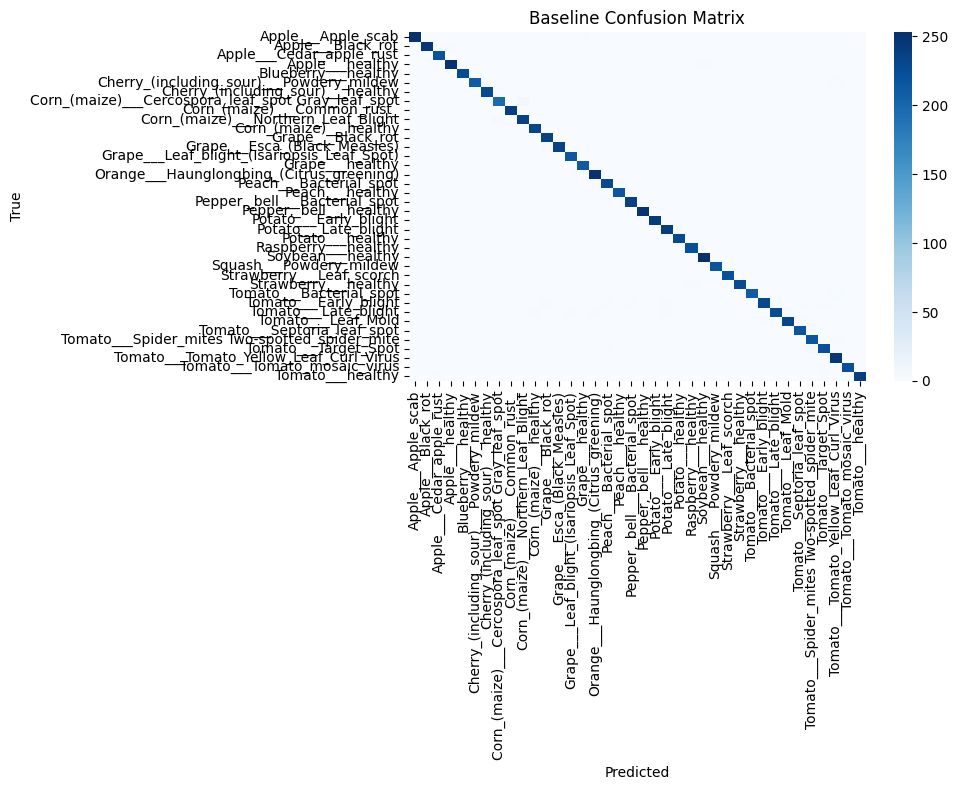

In [ ]:
#BUILDING CONFUSION MATRIX
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=False, xticklabels=train_ds.classes, yticklabels=train_ds.classes, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Baseline Confusion Matrix')
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/plant_disease_project/baseline_confusion_matrix.png', dpi=150)
plt.show()

# STEP A6: EXPORT FOR BACKEND

In [ ]:
#CLASS MAPPING
import json

class_mapping = {i: cls_name for i, cls_name in enumerate(train_ds.classes)}
with open('/content/drive/MyDrive/plant_disease_project/class_mapping.json', 'w') as f:
    json.dump(class_mapping, f, indent=2)

print(class_mapping)

{0: 'Apple___Apple_scab', 1: 'Apple___Black_rot', 2: 'Apple___Cedar_apple_rust', 3: 'Apple___healthy', 4: 'Blueberry___healthy', 5: 'Cherry_(including_sour)___Powdery_mildew', 6: 'Cherry_(including_sour)___healthy', 7: 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 8: 'Corn_(maize)___Common_rust_', 9: 'Corn_(maize)___Northern_Leaf_Blight', 10: 'Corn_(maize)___healthy', 11: 'Grape___Black_rot', 12: 'Grape___Esca_(Black_Measles)', 13: 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 14: 'Grape___healthy', 15: 'Orange___Haunglongbing_(Citrus_greening)', 16: 'Peach___Bacterial_spot', 17: 'Peach___healthy', 18: 'Pepper,_bell___Bacterial_spot', 19: 'Pepper,_bell___healthy', 20: 'Potato___Early_blight', 21: 'Potato___Late_blight', 22: 'Potato___healthy', 23: 'Raspberry___healthy', 24: 'Soybean___healthy', 25: 'Squash___Powdery_mildew', 26: 'Strawberry___Leaf_scorch', 27: 'Strawberry___healthy', 28: 'Tomato___Bacterial_spot', 29: 'Tomato___Early_blight', 30: 'Tomato___Late_blight', 31: 'To

In [ ]:
!ls -la /content/drive/MyDrive/plant_disease_project/

total 2917815
-rw------- 1 root root     369738 Sep  6 05:58 baseline_confusion_matrix.png
-rw------- 1 root root       1394 Sep  6 05:58 class_mapping.json
-rw------- 1 root root 2897709187 Sep  6 05:09 dataset.zip
-rw------- 1 root root      30906 Sep  6 05:57 model_training.ipynb
-rw------- 1 root root   44864651 Aug 31 06:49 resnet18_augmented.pt
-rw------- 1 root root   44864523 Sep  6 05:41 resnet18_baseline.pt


# STEP A7: AUGMENTATION DESIGN

In [ ]:
#BUILDING AUGMENTATION PIPELINE
from torchvision import transforms

train_tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.RandomRotation(30),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.1)),
])


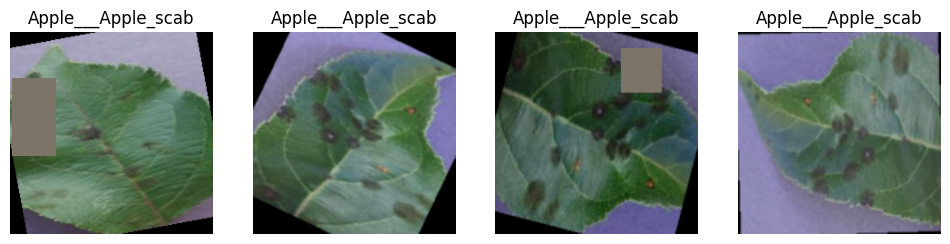

In [ ]:
#SANITY CHECKING
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt

sample_ds = ImageFolder(train_root, transform=train_tf_aug)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    img, label = sample_ds[i]
    img = img.permute(1, 2, 0).numpy()
    img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    ax.imshow(img.clip(0, 1))
    ax.set_title(train_ds.classes[label])
    ax.axis('off')
plt.show()

# STEP A8: RETRAINING WITH AUGMENTED DATA

In [ ]:
train_ds_aug = ImageFolder(train_root, transform=train_tf_aug)
train_dl_aug = DataLoader(train_ds_aug, batch_size=32, shuffle=True, num_workers=2)

In [ ]:
model_aug = models.resnet18(weights='IMAGENET1K_V1')

for name, param in model_aug.named_parameters():
    if not name.startswith('layer4') and not name.startswith('fc'):
        param.requires_grad = False

model_aug.fc = nn.Linear(model_aug.fc.in_features, num_classes)
model_aug = model_aug.to('cuda')

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer_aug = optim.Adam(filter(lambda p: p.requires_grad, model_aug.parameters()), lr=0.001)
best_val_acc_aug = 0.0
num_epochs = 12

for epoch in range(num_epochs):
    model_aug.train()
    train_loss, train_correct, train_total = 0, 0, 0
    for imgs, labels in train_dl_aug:
        imgs, labels = imgs.to('cuda'), labels.to('cuda')
        optimizer_aug.zero_grad()
        outputs = model_aug(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_aug.step()
        train_loss += loss.item() * imgs.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model_aug.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for imgs, labels in val_dl:  # UN-augmented — same val set used for baseline
            imgs, labels = imgs.to('cuda'), labels.to('cuda')
            outputs = model_aug(imgs)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total
    print(f"Epoch {epoch+1}/{num_epochs} | train_loss {train_loss/train_total:.4f} "
          f"| train_acc {train_acc:.3f} | val_acc {val_acc:.3f}")

    if val_acc > best_val_acc_aug:
        best_val_acc_aug = val_acc
        torch.save(model_aug.state_dict(), '/content/drive/MyDrive/plant_disease_project/resnet18_augmented.pt')
        print("  ↳ new best augmented model saved")

In [ ]:
!ls -la /content/drive/MyDrive/plant_disease_project/